The dataset used : https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia/data

All images are in jpeg format. As we can't use libraries to deal with this format, we have to use pgm format, which can be turned into numpy ndarray for scikit-learn.

The bash script :

ROOT_DIR="${1:-.}"

find "$ROOT_DIR" -type f \( -iname "*.jpg" -o -iname "*.jpeg" \) | while read img; do
    out="${img%.*}.pgm"
    echo "Converting $img → $out"

    if convert "$img" "$out"; then
        rm "$img"
        echo "Removed $img"
    else
        echo "Failed: $img"
    fi
done

echo "Done."

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\d'
<>:15: SyntaxWarning: invalid escape sequence '\d'
<>:16: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\d'
<>:15: SyntaxWarning: invalid escape sequence '\d'
<>:16: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_25770/1479770472.py:13: SyntaxWarning: invalid escape sequence '\s'
  b"(^P5\s(?:\s*#.*[\r\n])*"
/tmp/ipykernel_25770/1479770472.py:14: SyntaxWarning: invalid escape sequence '\d'
  b"(\d+)\s(?:\s*#.*[\r\n])*"
/tmp/ipykernel_25770/1479770472.py:15: SyntaxWarning: invalid escape sequence '\d'
  b"(\d+)\s(?:\s*#.*[\r\n])*"
/tmp/ipykernel_25770/1479770472.py:16: SyntaxWarning: invalid escape sequence '\d'
  b"(\d+)\s(?:\s*#.*[\r\n]\s)*)", buffer).groups()


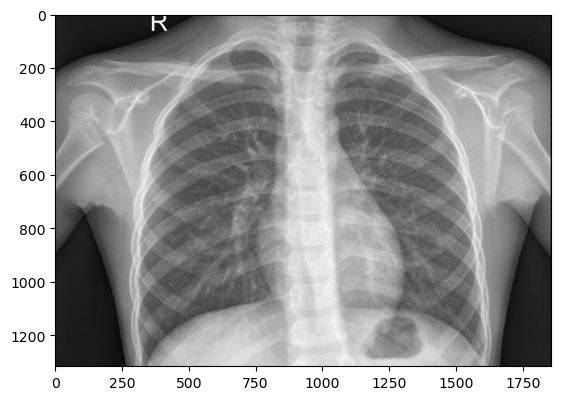

numpy.ndarray

In [6]:
import re

def read_pgm(filename, byteorder='>'):
    """Return image data from a raw PGM file as numpy array.

    Format specification: http://netpbm.sourceforge.net/doc/pgm.html

    """
    with open(filename, 'rb') as f:
        buffer = f.read()
    try:
        header, width, height, maxval = re.search(
            b"(^P5\s(?:\s*#.*[\r\n])*"
            b"(\d+)\s(?:\s*#.*[\r\n])*"
            b"(\d+)\s(?:\s*#.*[\r\n])*"
            b"(\d+)\s(?:\s*#.*[\r\n]\s)*)", buffer).groups()
    except AttributeError:
        raise ValueError("Not a raw PGM file: '%s'" % filename)
    return np.frombuffer(buffer,
                            dtype='u1' if int(maxval) < 256 else byteorder+'u2',
                            count=int(width)*int(height),
                            offset=len(header)
                            ).reshape((int(height), int(width)))




image = read_pgm("archive/chest_xray/test/NORMAL/IM-0001-0001.pgm", byteorder='<')
plt.imshow(image, plt.cm.gray)
plt.show()
type(image)

In [ ]:
x_train, x_test, y_test, y_train = train_test_split(data, labels, test_size=0.2, shuffle=True, stratify=labels) # data and labels doesn't exist yet
# no need to do it because images are already splitted
# or re-split the "train" folder

training

In [ ]:
classifier = SVC()

parameters = [{'gamma' : [0.01, 0.001, 0.0001], 'C' : [1, 10, 100, 1000]}]

grid_search = GridSearchCV(classifier, parameters)

grid_search.fit(x_train, y_train)

test performance

In [ ]:
best_estimator = grid_search.best_estimator_
y_prediction = best_estimator.predict(x_test)

score = accuracy_score(y_prediction, y_test)

print('{}% of samples were correctly classified', format(str(score * 100)))